<a href="https://colab.research.google.com/github/nurfahdilla293/praktikum_evaluasi_model.ipynb/blob/main/Praktikum_4_Pipeline_Titanic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum: Bangun Pipeline Titanic dan Bandingkan Fitur

**Mata kuliah:** Machine Learning
**Nama:** Nurvahdilla
**Tools:** Google Colab, scikit-learn

## Tujuan
1. Membuat split data yang terstratifikasi
2. Mendefinisikan kolom numerik dan kategorikal
3. Membangun `ColumnTransformer` + `Pipeline` dengan Logistic Regression
4. Membandingkan model dengan **semua fitur** vs **fitur terpilih**
5. Melaporkan **akurasi** dan **F1-score**

**Output:** Pipeline + daftar fitur + tabel metrik.

## 1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
sns.set_style("whitegrid")

## 2. Load Dataset

Dataset Titanic diambil dari `seaborn`, jadi tidak perlu upload file manual.

In [2]:
titanic = sns.load_dataset("titanic")
print("Ukuran data:", titanic.shape)
titanic.head()

Ukuran data: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Eksplorasi Data Singkat (EDA)

In [3]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [4]:
# Cek missing values pada kolom yang akan dipakai
kolom_cek = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
missing = titanic[kolom_cek].isna().sum().to_frame("jumlah_missing")
missing["persen"] = (missing["jumlah_missing"] / len(titanic) * 100).round(2)
missing

,jumlah_missing,persen
survived,0,0.00
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22


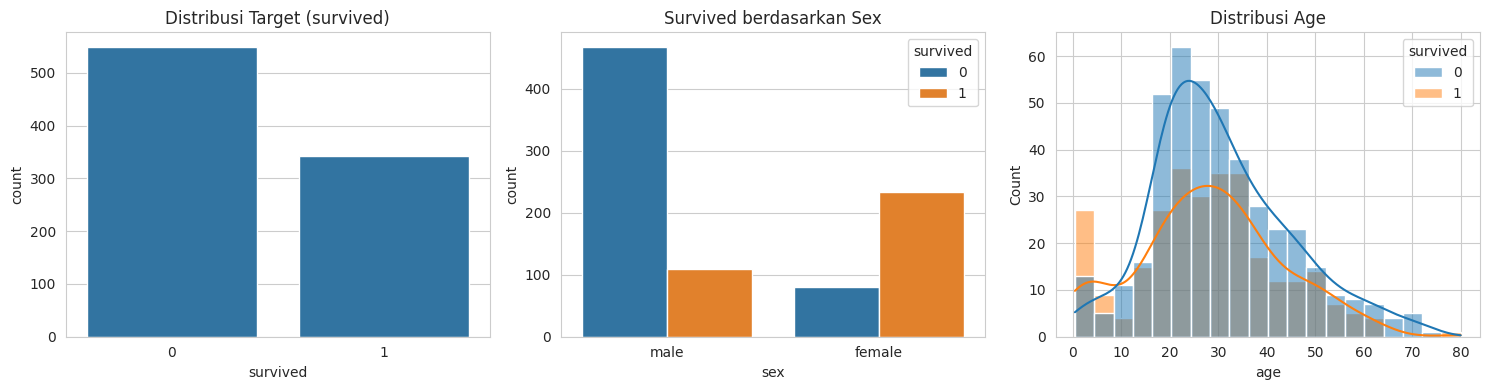

survived
0    0.616
1    0.384
Name: proportion, dtype: float64


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x="survived", data=titanic, ax=ax[0])
ax[0].set_title("Distribusi Target (survived)")

sns.countplot(x="sex", hue="survived", data=titanic, ax=ax[1])
ax[1].set_title("Survived berdasarkan Sex")

sns.histplot(data=titanic, x="age", hue="survived", kde=True, ax=ax[2])
ax[2].set_title("Distribusi Age")

plt.tight_layout()
plt.show()

print(titanic["survived"].value_counts(normalize=True).round(3))

**Catatan:** `age` dan `embarked` punya missing values, jadi harus di-*impute* di dalam pipeline. Kelas target juga agak tidak seimbang, jadi split harus **stratifikasi** dan metrik F1 ikut dilaporkan, bukan hanya akurasi.

## 4. Siapkan Fitur (X) dan Target (y)

Skenario fitur yang dibandingkan nanti:

- **Fitur terpilih** (sesuai soal): `age`, `fare`, `sex`, `embarked`
- **Semua fitur**: `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`

Kolom `alive`, `who`, `adult_male`, `class`, `embark_town`, dan `alone` tidak dipakai karena duplikat/turunan dari kolom lain (`alive` bahkan identik dengan target, jadi bisa menyebabkan *data leakage*).

In [6]:
fitur_terpilih = ["age", "fare", "sex", "embarked"]
fitur_semua    = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]

X = titanic[fitur_semua]      # simpan semua dulu, nanti disubset sesuai skenario
y = titanic["survived"]

print("X:", X.shape, "| y:", y.shape)

X: (891, 7) | y: (891,)


## 5. Langkah 1 - Split Data Terstratifikasi

`stratify=y` menjaga proporsi kelas survived/tidak sama di data latih dan data uji.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nProporsi survived (train):", y_train.mean().round(3))
print("Proporsi survived (test) :", y_test.mean().round(3))

Train: (712, 7) | Test: (179, 7)

Proporsi survived (train): 0.383
Proporsi survived (test) : 0.385


## 6. Langkah 2 - Definisikan Kolom

Kolom dipisah berdasarkan tipe supaya tiap jenis mendapat preprocessing yang sesuai.

In [8]:
# Skenario A: fitur terpilih (sesuai slide)
num_cols_sel = ["age", "fare"]
cat_cols_sel = ["sex", "embarked"]

# Skenario B: semua fitur
num_cols_all = ["pclass", "age", "sibsp", "parch", "fare"]
cat_cols_all = ["sex", "embarked"]

print("Terpilih -> num:", num_cols_sel, "| cat:", cat_cols_sel)
print("Semua    -> num:", num_cols_all, "| cat:", cat_cols_all)

Terpilih -> num: ['age', 'fare'] | cat: ['sex', 'embarked']
Semua    -> num: ['pclass', 'age', 'sibsp', 'parch', 'fare'] | cat: ['sex', 'embarked']


## 7. Langkah 3 - Bangun ColumnTransformer dan Pipeline

- **Numerik:** imputasi *median* -> `StandardScaler`
- **Kategorikal:** imputasi *most_frequent* -> `OneHotEncoder`
- **Model:** `LogisticRegression(max_iter=1000)`

Semua preprocessing ada di dalam pipeline, jadi imputer/scaler hanya di-*fit* pada data latih (tidak ada kebocoran data ke data uji).

In [9]:
def buat_pipeline(num_cols, cat_cols):
    num_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocess = ColumnTransformer([
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ])

    pipe = Pipeline([
        ("prep", preprocess),
        ("model", LogisticRegression(max_iter=1000))
    ])
    return pipe

# Pipeline untuk fitur terpilih (versi utama sesuai slide)
pipe = buat_pipeline(num_cols_sel, cat_cols_sel)
pipe

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'embarked'])])),
                ('model', LogisticRegression(max_iter=1000))])

## 8. Latih Pipeline (Fitur Terpilih) dan Prediksi

In [10]:
pipe.fit(X_train[fitur_terpilih], y_train)
y_pred = pipe.predict(X_test[fitur_terpilih])

print("Akurasi :", round(accuracy_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=["Meninggal (0)", "Selamat (1)"]))

Akurasi : 0.7765
F1-score: 0.697

               precision    recall  f1-score   support

Meninggal (0)       0.80      0.85      0.82       110
  Selamat (1)       0.73      0.67      0.70        69

     accuracy                           0.78       179
    macro avg       0.77      0.76      0.76       179
 weighted avg       0.77      0.78      0.77       179



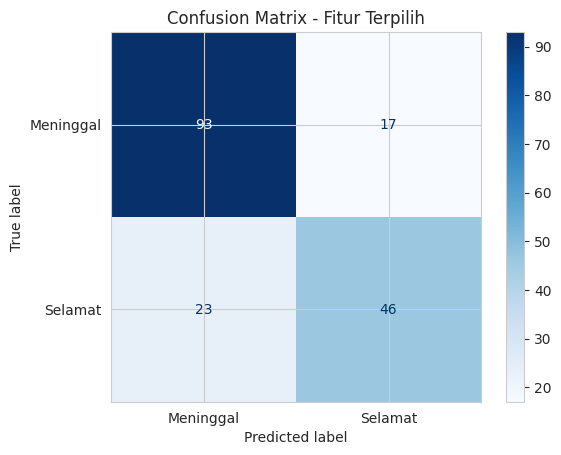

In [11]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Meninggal", "Selamat"]).plot(cmap="Blues")
plt.title("Confusion Matrix - Fitur Terpilih")
plt.show()

## 9. Langkah 4 - Bandingkan Semua Fitur vs Fitur Terpilih

Kedua skenario memakai split yang sama (`X_train`, `X_test`) supaya perbandingannya adil. Selain hasil pada data uji, saya tambahkan **5-fold stratified cross-validation** pada data latih supaya kesimpulan tidak bergantung pada satu kali split saja.

In [14]:
skenario = {
    "Fitur terpilih": (fitur_terpilih, num_cols_sel, cat_cols_sel),
    "Semua fitur":    (fitur_semua,    num_cols_all, cat_cols_all),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
hasil = []
model_terlatih = {}

for nama, (fitur, num_c, cat_c) in skenario.items():
    p = buat_pipeline(num_c, cat_c)
    p.fit(X_train[fitur], y_train)
    pred = p.predict(X_test[fitur])
    model_terlatih[nama] = p

    cv_acc = cross_val_score(p, X_train[fitur], y_train, cv=skf, scoring="accuracy")
    cv_f1  = cross_val_score(p, X_train[fitur], y_train, cv=skf, scoring="f1")

    hasil.append({
        "Skenario": nama,
        "Jumlah fitur": len(fitur),
        "Akurasi (test)": accuracy_score(y_test, pred),
        "F1 (test)": f1_score(y_test, pred),
        "Akurasi CV (mean)": cv_acc.mean(),
        "F1 CV (mean)": cv_f1.mean(),
        "F1 CV (std)": cv_f1.std(),
    })

tabel_metrik = pd.DataFrame(hasil).set_index("Skenario").round(4)
tabel_metrik

,Jumlah fitur,Akurasi (test),F1 (test),Akurasi CV (mean),F1 CV (mean),F1 CV (std)
Skenario,,,,,,
Fitur terpilih,4,0.7765,0.6970,0.7823,0.710,0.0297
Semua fitur,7,0.8045,0.7244,0.7963,0.726,0.0341


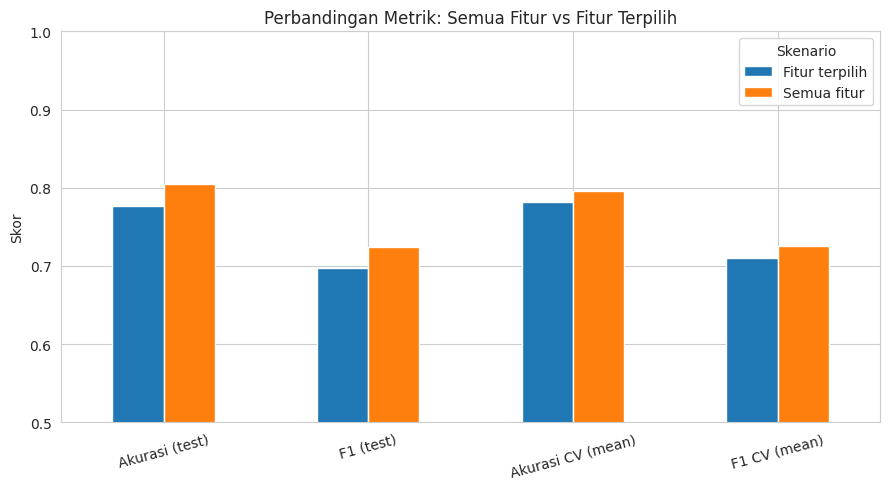

In [15]:
# Visualisasi perbandingan
plot_df = tabel_metrik[["Akurasi (test)", "F1 (test)", "Akurasi CV (mean)", "F1 CV (mean)"]]
ax = plot_df.T.plot(kind="bar", figsize=(9, 5), rot=15)
ax.set_title("Perbandingan Metrik: Semua Fitur vs Fitur Terpilih")
ax.set_ylabel("Skor")
ax.set_ylim(0.5, 1.0)
plt.legend(title="Skenario")
plt.tight_layout()
plt.show()

## 10. Daftar Fitur dan Koefisien Model

In [16]:
for nama, p in model_terlatih.items():
    nama_fitur = p.named_steps["prep"].get_feature_names_out()
    koef = p.named_steps["model"].coef_[0]
    df_koef = (pd.DataFrame({"fitur": nama_fitur, "koefisien": koef})
                 .assign(abs_koef=lambda d: d["koefisien"].abs())
                 .sort_values("abs_koef", ascending=False)
                 .drop(columns="abs_koef")
                 .reset_index(drop=True))
    print(f"=== {nama} ({len(nama_fitur)} fitur setelah preprocessing) ===")
    display(df_koef.round(3))
    print()

=== Fitur terpilih (7 fitur setelah preprocessing) ===


,fitur,koefisien
0,cat__sex_male,-1.198
1,cat__sex_female,1.162
2,num__fare,0.564
3,cat__embarked_C,0.326
4,cat__embarked_S,-0.304
5,num__age,-0.171
6,cat__embarked_Q,-0.058



=== Semua fitur (10 fitur setelah preprocessing) ===


,fitur,koefisien
0,cat__sex_male,-1.321
1,cat__sex_female,1.299
2,num__pclass,-0.922
3,num__age,-0.503
4,cat__embarked_S,-0.358
5,cat__embarked_Q,0.305
6,num__sibsp,-0.261
7,num__fare,0.100
8,num__parch,-0.066
9,cat__embarked_C,0.032


## 11. Output Akhir

In [17]:
print("DAFTAR FITUR")
print("- Fitur terpilih :", fitur_terpilih)
print("- Semua fitur    :", fitur_semua)
print()
print("PIPELINE (fitur terpilih):")
display(pipe)
print()
print("TABEL METRIK:")
display(tabel_metrik)

DAFTAR FITUR
- Fitur terpilih : ['age', 'fare', 'sex', 'embarked']
- Semua fitur    : ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

PIPELINE (fitur terpilih):


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'embarked'])])),
                ('model', LogisticRegression(max_iter=1000))])


TABEL METRIK:


,Jumlah fitur,Akurasi (test),F1 (test),Akurasi CV (mean),F1 CV (mean),F1 CV (std)
Skenario,,,,,,
Fitur terpilih,4,0.7765,0.6970,0.7823,0.710,0.0297
Semua fitur,7,0.8045,0.7244,0.7963,0.726,0.0341


## 12. Kesimpulan

Isi kesimpulan sesuai angka yang keluar di tabel metrik di atas. Kerangkanya:

1. **Perbandingan skor.** Bandingkan Akurasi dan F1 antara "Semua fitur" dan "Fitur terpilih", baik di data uji maupun di cross-validation. Kalau selisihnya kecil (dan masih dalam rentang standar deviasi CV), berarti tambahan fitur tidak memberi peningkatan yang berarti.
2. **Peran fitur.** Lihat koefisien Logistic Regression: fitur dengan koefisien absolut besar (misalnya `sex`) paling berpengaruh terhadap prediksi.
3. **Mengapa F1 dilaporkan.** Kelas selamat/tidak tidak seimbang, jadi akurasi saja bisa menyesatkan. F1 menggabungkan precision dan recall untuk kelas positif (selamat).
4. **Manfaat Pipeline.** Imputasi, scaling, dan encoding ikut di-*fit* hanya pada data latih sehingga mencegah *data leakage*, dan seluruh alur bisa dipakai ulang dengan satu `fit` / `predict`.
5. **Keterbatasan.** Hanya satu split, satu model (Logistic Regression), dan fitur dasar. Pengembangan: rekayasa fitur (misalnya `title` dari nama, `family_size`), model lain, dan *hyperparameter tuning*.